In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os
import re
import ast
import itertools
from collections import Counter, defaultdict

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

Mounted at /content/drive


In [5]:
BASE_DIR = "/content/drive/MyDrive/thesis_movie_project"
PROCESSED_DIR = f"{BASE_DIR}/processed"
FIG_DIR = f"{BASE_DIR}/outputs/figures"

os.makedirs(FIG_DIR, exist_ok=True)

master = pd.read_csv(f"{PROCESSED_DIR}/thesis_master_final.csv", low_memory=False)
df_semantic_analysis = pd.read_csv(f"{PROCESSED_DIR}/df_semantic_analysis.csv", low_memory=False)
df_revenue_analysis_analysis = pd.read_csv(f"{PROCESSED_DIR}/df_revenue_analysis_analysis.csv", low_memory=False)
df_roi_analysis_analysis = pd.read_csv(f"{PROCESSED_DIR}/df_roi_analysis_analysis.csv", low_memory=False)

print("master:", master.shape)
print("df_semantic_analysis:", df_semantic_analysis.shape)
print("df_revenue_analysis_analysis:", df_revenue_analysis_analysis.shape)
print("df_roi_analysis_analysis:", df_roi_analysis_analysis.shape)

master: (89569, 22)
df_semantic_analysis: (42709, 27)
df_revenue_analysis: (8603, 28)
df_roi_analysis: (5707, 29)


In [6]:
import pandas as pd

# Load your final dataset
df = pd.read_csv("/content/drive/MyDrive/thesis_movie_project/processed/thesis_master_final.csv")

# Make sure release_year is numeric
df["release_year"] = pd.to_numeric(df["release_year"], errors="coerce")

# Count movies per year
movies_per_year = (
    df["release_year"]
    .dropna()
    .astype(int)
    .value_counts()
    .sort_index()
    .reset_index()
)

movies_per_year.columns = ["release_year", "movie_count"]

# Show all years
print(movies_per_year)

# Optional: save it
movies_per_year.to_csv("/content/drive/MyDrive/thesis_movie_project/processed/movies_per_year.csv", index=False)

     release_year  movie_count
0            1874            1
1            1878            1
2            1883            1
3            1887            1
4            1888            2
..            ...          ...
136          2021         6202
137          2022         7348
138          2023         6081
139          2024          764
140          2025            1

[141 rows x 2 columns]


In [7]:
# Basic text richness
df_semantic_analysis["overview_word_count"] = (
    df_semantic_analysis["overview"].fillna("").astype(str).str.split().str.len()
)

df_semantic_analysis["keyword_word_count"] = (
    df_semantic_analysis["keywords_clean"].fillna("").astype(str).str.split().str.len()
)

df_semantic_analysis["cast_word_count"] = (
    df_semantic_analysis["cast_clean"].fillna("").astype(str).str.split().str.len()
)

# Numeric safety
for col in ["runtime", "popularity", "vote_average", "vote_count", "release_year"]:
    df_semantic_analysis[col] = pd.to_numeric(df_semantic_analysis[col], errors="coerce")

master["release_year"] = pd.to_numeric(master["release_year"], errors="coerce")
master["budget_clean"] = pd.to_numeric(master["budget"], errors="coerce")
master["revenue_clean"] = pd.to_numeric(master["revenue"], errors="coerce")

master.loc[master["budget_clean"] <= 0, "budget_clean"] = np.nan
master.loc[master["revenue_clean"] <= 0, "revenue_clean"] = np.nan

master["roi_clean"] = np.where(
    master["budget_clean"].notna() & master["revenue_clean"].notna(),
    master["revenue_clean"] / master["budget_clean"],
    np.nan
)

df_semantic_analysis["decade"] = (df_semantic_analysis["release_year"] // 10) * 10
master["decade"] = (master["release_year"] // 10) * 10

In [8]:
# Because genres_clean was flattened into text, reconstruct genres using a fixed vocabulary
GENRE_VOCAB = [
    "Action", "Adventure", "Animation", "Comedy", "Crime", "Documentary",
    "Drama", "Family", "Fantasy", "History", "Horror", "Music", "Mystery",
    "Romance", "Science Fiction", "TV Movie", "Thriller", "War", "Western"
]

genre_patterns = {g: re.compile(rf"\b{re.escape(g.lower())}\b") for g in GENRE_VOCAB}

def extract_genres_from_text(text):
    text = str(text).lower()
    found = []
    for genre, pattern in genre_patterns.items():
        if pattern.search(text):
            found.append(genre)
    return found

df_semantic_analysis["genre_list"] = df_semantic_analysis["genres_clean"].fillna("").apply(extract_genres_from_text)
df_semantic_analysis["genre_count"] = df_semantic_analysis["genre_list"].apply(len)

print(df_semantic_analysis[["genres_clean", "genre_list", "genre_count"]].head(10))

                          genres_clean  \
0                          Drama Crime   
1                               Comedy   
2                                Drama   
3  Action Comedy Music Romance Western   
4                                Crime   
5                               Comedy   
6                              Mystery   
7                          Crime Drama   
8                 Crime Drama Thriller   
9                 Comedy Romance Drama   

                                  genre_list  genre_count  
0                             [Crime, Drama]            2  
1                                   [Comedy]            1  
2                                    [Drama]            1  
3  [Action, Comedy, Music, Romance, Western]            5  
4                                    [Crime]            1  
5                                   [Comedy]            1  
6                                  [Mystery]            1  
7                             [Crime, Drama]            2

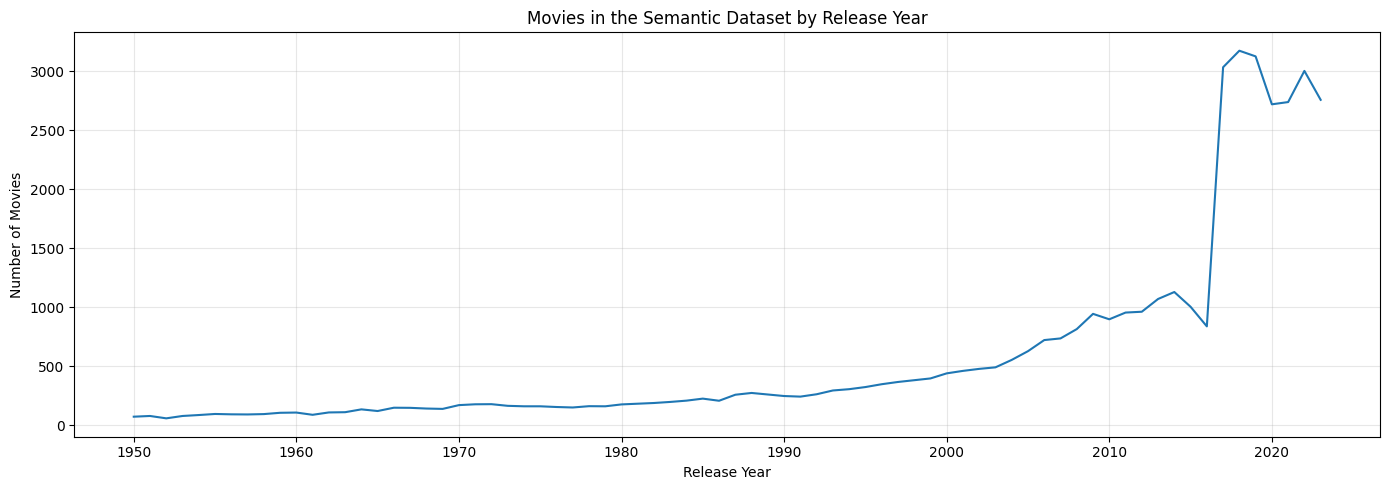

In [9]:
year_counts = (
    df_semantic_analysis["release_year"]
    .dropna()
    .astype(int)
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(14, 5))
plt.plot(year_counts.index, year_counts.values)
plt.title("Movies in the Semantic Dataset by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Movies")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/eda_movies_by_year.png", dpi=300)
plt.show()

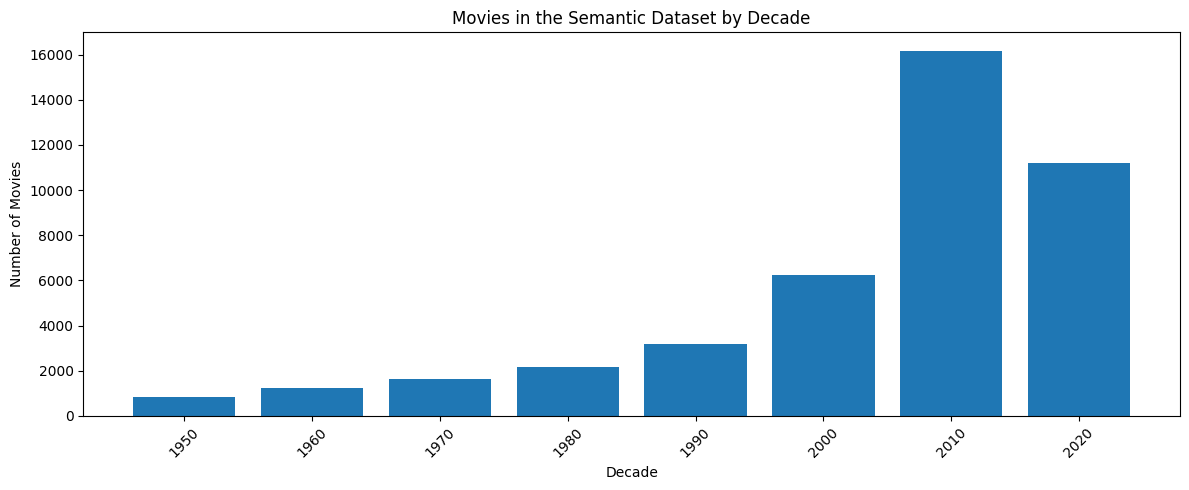

In [10]:
decade_counts = (
    df_semantic_analysis["decade"]
    .dropna()
    .astype(int)
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(12, 5))
plt.bar(decade_counts.index.astype(str), decade_counts.values)
plt.title("Movies in the Semantic Dataset by Decade")
plt.xlabel("Decade")
plt.ylabel("Number of Movies")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/eda_movies_by_decade.png", dpi=300)
plt.show()

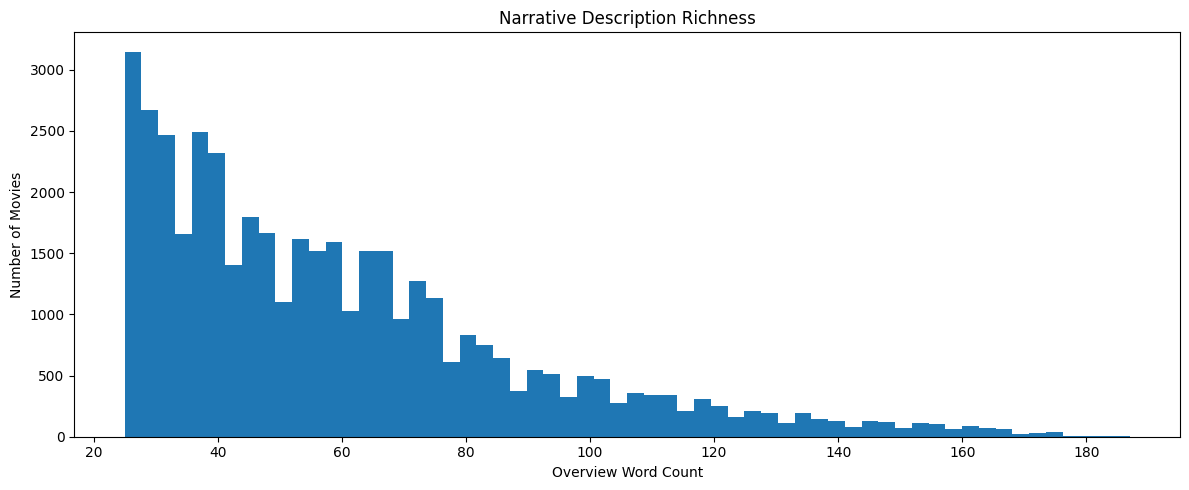

count    42709.000000
mean        59.990072
std         30.356525
min         25.000000
25%         36.000000
50%         53.000000
75%         74.000000
max        187.000000
Name: overview_word_count, dtype: float64


In [11]:
plt.figure(figsize=(12, 5))
plt.hist(df_semantic_analysis["overview_word_count"].dropna(), bins=60)
plt.title("Narrative Description Richness")
plt.xlabel("Overview Word Count")
plt.ylabel("Number of Movies")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/eda_overview_word_count.png", dpi=300)
plt.show()

print(df_semantic_analysis["overview_word_count"].describe())

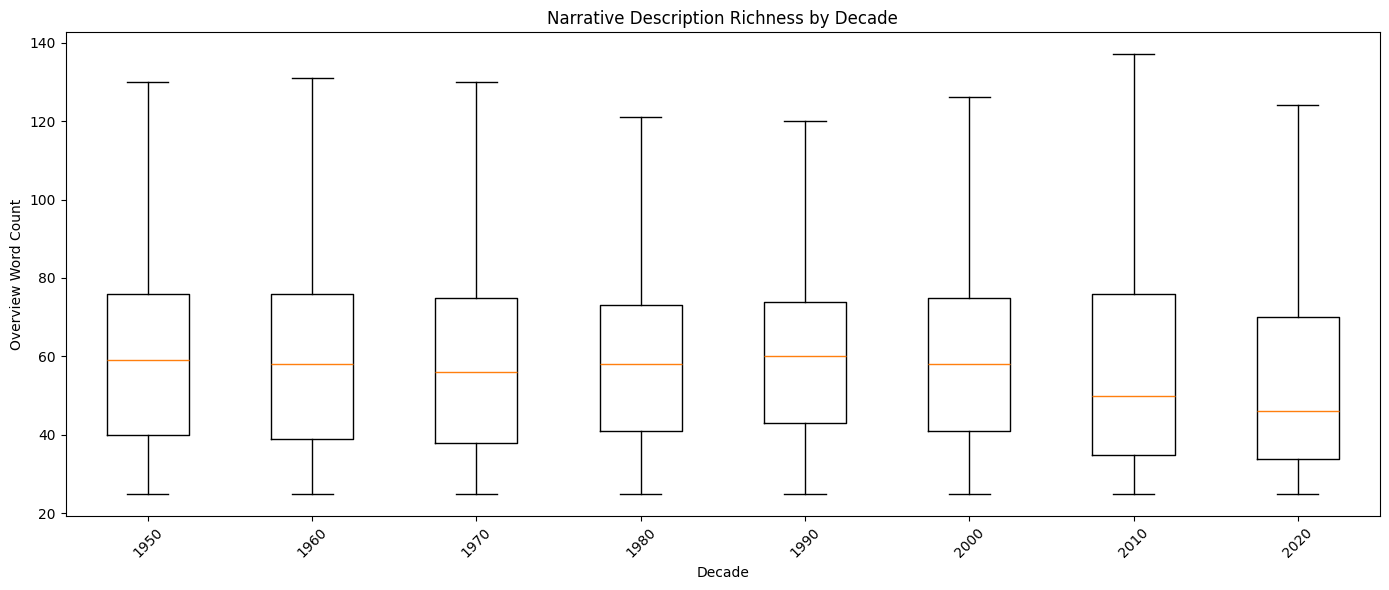

In [12]:
# Keep selected decades with enough observations
valid_decades = (
    df_semantic_analysis["decade"]
    .dropna()
    .astype(int)
    .value_counts()
    .sort_index()
)

selected_decades = valid_decades.index.tolist()
box_data = [
    df_semantic_analysis.loc[df_semantic_analysis["decade"] == d, "overview_word_count"].dropna()
    for d in selected_decades
]

plt.figure(figsize=(14, 6))
plt.boxplot(box_data, tick_labels=[str(int(d)) for d in selected_decades], showfliers=False)
plt.title("Narrative Description Richness by Decade")
plt.xlabel("Decade")
plt.ylabel("Overview Word Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/eda_overview_by_decade_boxplot.png", dpi=300)
plt.show()

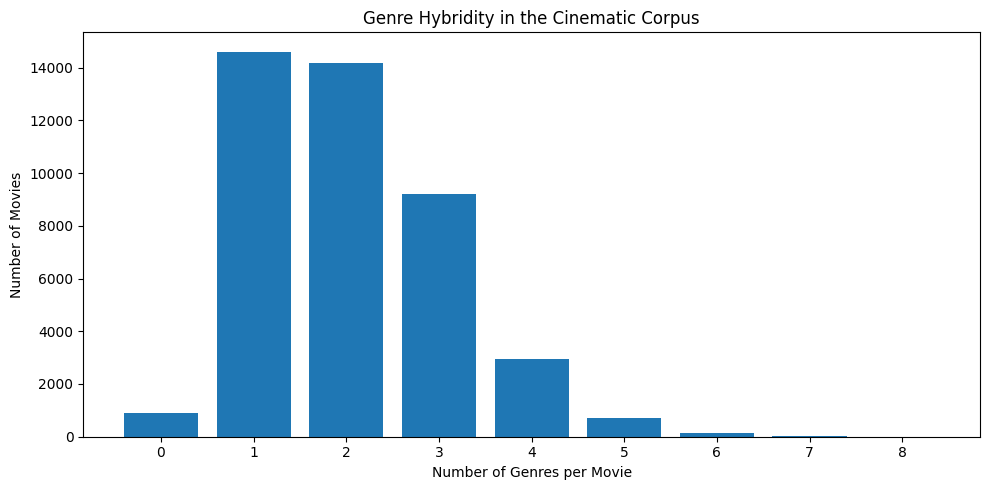

34.203563651689336 % single-genre
63.70554215739072 % multi-genre


In [13]:
genre_count_dist = df_semantic_analysis["genre_count"].value_counts().sort_index()

plt.figure(figsize=(10, 5))
plt.bar(genre_count_dist.index.astype(str), genre_count_dist.values)
plt.title("Genre Hybridity in the Cinematic Corpus")
plt.xlabel("Number of Genres per Movie")
plt.ylabel("Number of Movies")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/eda_genre_hybridity.png", dpi=300)
plt.show()

print((df_semantic_analysis["genre_count"] == 1).mean() * 100, "% single-genre")
print((df_semantic_analysis["genre_count"] >= 2).mean() * 100, "% multi-genre")

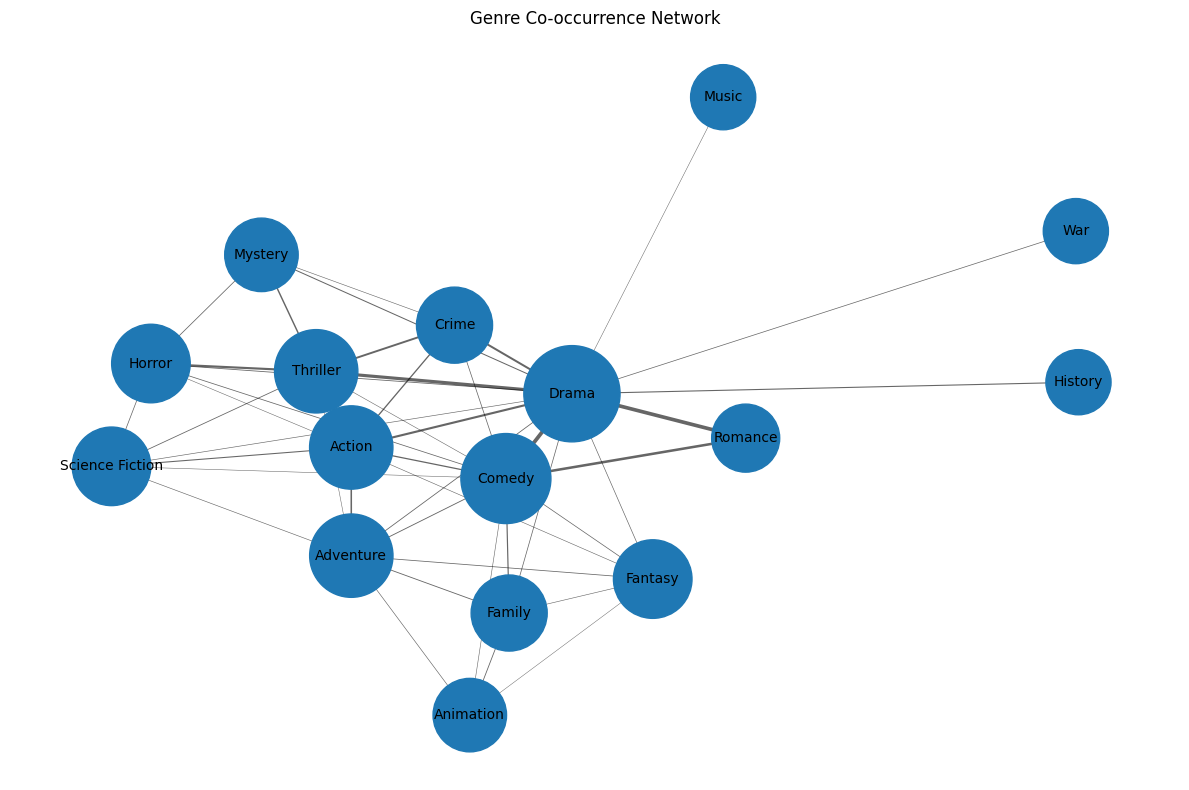

In [14]:
pair_counter = Counter()

for genres in df_semantic_analysis["genre_list"]:
    genres = sorted(set(genres))
    if len(genres) >= 2:
        for pair in itertools.combinations(genres, 2):
            pair_counter[pair] += 1

# Build graph from strongest co-occurrences only
G_genre = nx.Graph()

for (g1, g2), w in pair_counter.items():
    if w >= 500:   # threshold to keep the graph readable
        G_genre.add_edge(g1, g2, weight=w)

plt.figure(figsize=(12, 8))
pos = nx.spring_layout(G_genre, seed=42, k=0.8)

edge_widths = [G_genre[u][v]["weight"] / 1500 for u, v in G_genre.edges()]
node_sizes = [2000 + 200 * G_genre.degree(n) for n in G_genre.nodes()]

nx.draw_networkx_nodes(G_genre, pos, node_size=node_sizes)
nx.draw_networkx_edges(G_genre, pos, width=edge_widths, alpha=0.6)
nx.draw_networkx_labels(G_genre, pos, font_size=10)

plt.title("Genre Co-occurrence Network")
plt.axis("off")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/eda_genre_cooccurrence_network.png", dpi=300)
plt.show()

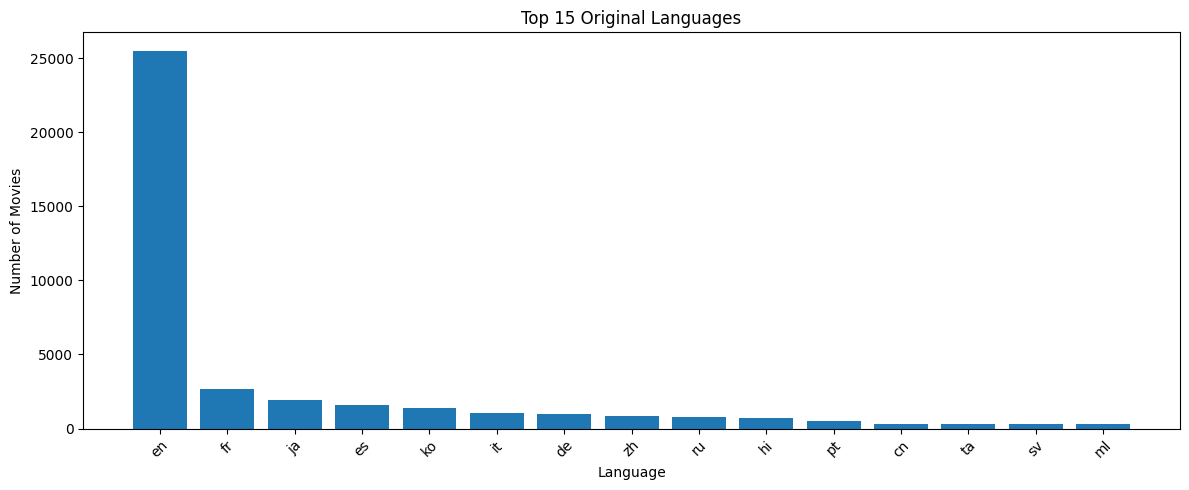

In [15]:
lang_counts = (
    df_semantic_analysis["original_language"]
    .fillna("UNKNOWN")
    .astype(str)
    .replace("", "UNKNOWN")
    .value_counts()
    .head(15)
)

plt.figure(figsize=(12, 5))
plt.bar(lang_counts.index, lang_counts.values)
plt.title("Top 15 Original Languages")
plt.xlabel("Language")
plt.ylabel("Number of Movies")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/eda_top_languages.png", dpi=300)
plt.show()

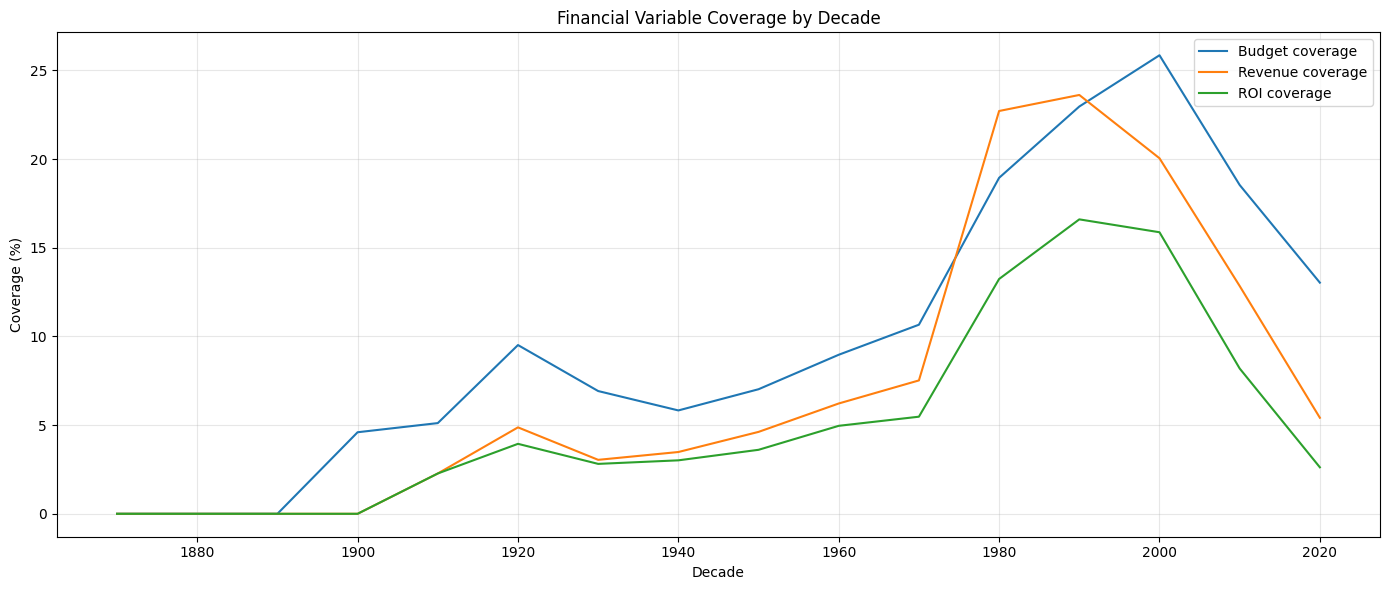

,decade,total_movies,valid_budget,valid_revenue,valid_roi,budget_coverage_pct,revenue_coverage_pct,roi_coverage_pct
1,1880.0,4,0,0,0,0.000000,0.000000,0.000000
2,1890.0,75,0,0,0,0.000000,0.000000,0.000000
3,1900.0,87,4,0,0,4.597701,0.000000,0.000000
4,1910.0,176,9,4,4,5.113636,2.272727,2.272727
5,1920.0,431,41,21,17,9.512761,4.872390,3.944316
6,1930.0,1315,91,40,37,6.920152,3.041825,2.813688
7,1940.0,1493,87,52,45,5.827194,3.482920,3.014066
8,1950.0,2079,146,96,75,7.022607,4.617605,3.607504
9,1960.0,2621,235,163,130,8.966043,6.219000,4.959939
10,1970.0,3471,370,261,190,10.659752,7.519447,5.473927


In [16]:
finance_by_decade = master.groupby("decade").agg(
    total_movies=("id", "size"),
    valid_budget=("budget_clean", lambda x: x.notna().sum()),
    valid_revenue=("revenue_clean", lambda x: x.notna().sum()),
    valid_roi=("roi_clean", lambda x: x.notna().sum())
).reset_index()

finance_by_decade["budget_coverage_pct"] = finance_by_decade["valid_budget"] / finance_by_decade["total_movies"] * 100
finance_by_decade["revenue_coverage_pct"] = finance_by_decade["valid_revenue"] / finance_by_decade["total_movies"] * 100
finance_by_decade["roi_coverage_pct"] = finance_by_decade["valid_roi"] / finance_by_decade["total_movies"] * 100

finance_by_decade = finance_by_decade.sort_values("decade")

plt.figure(figsize=(14, 6))
plt.plot(finance_by_decade["decade"], finance_by_decade["budget_coverage_pct"], label="Budget coverage")
plt.plot(finance_by_decade["decade"], finance_by_decade["revenue_coverage_pct"], label="Revenue coverage")
plt.plot(finance_by_decade["decade"], finance_by_decade["roi_coverage_pct"], label="ROI coverage")
plt.title("Financial Variable Coverage by Decade")
plt.xlabel("Decade")
plt.ylabel("Coverage (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/eda_finance_coverage_by_decade.png", dpi=300)
plt.show()

finance_by_decade.tail(15)

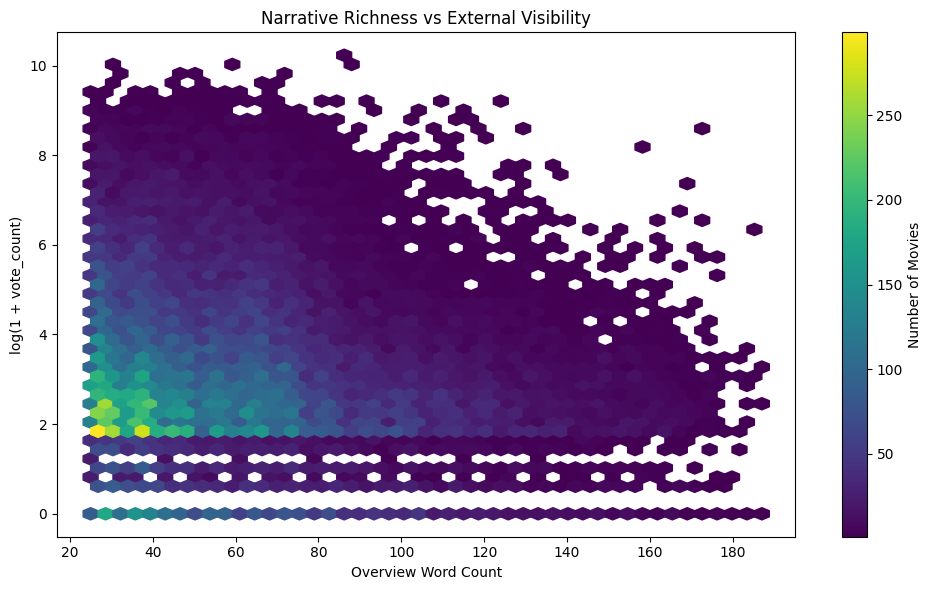

In [17]:
plot_df = df_semantic_analysis.copy()
plot_df["log_vote_count"] = np.log1p(pd.to_numeric(plot_df["vote_count"], errors="coerce"))

plt.figure(figsize=(10, 6))
plt.hexbin(
    plot_df["overview_word_count"],
    plot_df["log_vote_count"],
    gridsize=45,
    mincnt=1
)
plt.colorbar(label="Number of Movies")
plt.title("Narrative Richness vs External Visibility")
plt.xlabel("Overview Word Count")
plt.ylabel("log(1 + vote_count)")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/eda_narrative_richness_vs_visibility.png", dpi=300)
plt.show()

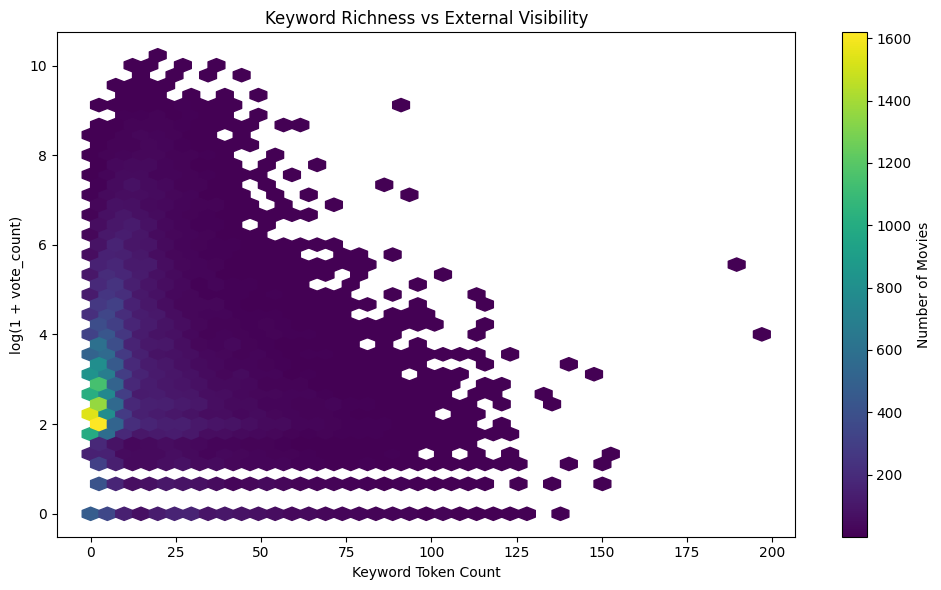

In [18]:
plt.figure(figsize=(10, 6))
plt.hexbin(
    df_semantic_analysis["keyword_word_count"],
    np.log1p(pd.to_numeric(df_semantic_analysis["vote_count"], errors="coerce")),
    gridsize=40,
    mincnt=1
)
plt.colorbar(label="Number of Movies")
plt.title("Keyword Richness vs External Visibility")
plt.xlabel("Keyword Token Count")
plt.ylabel("log(1 + vote_count)")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/eda_keyword_richness_vs_visibility.png", dpi=300)
plt.show()

In [19]:
eda_summary = pd.DataFrame({
    "metric": [
        "Movies in semantic core",
        "Median release year",
        "Median overview word count",
        "Mean genre count",
        "Revenue-valid movies",
        "ROI-valid movies"
    ],
    "value": [
        len(df_semantic_analysis),
        int(df_semantic_analysis["release_year"].median()),
        float(df_semantic_analysis["overview_word_count"].median()),
        round(df_semantic_analysis["genre_count"].mean(), 2),
        len(df_revenue_analysis),
        len(df_roi_analysis)
    ]
})

eda_summary

,metric,value
0,Movies in semantic core,42709.00
1,Median release year,2016.00
2,Median overview word count,53.00
3,Mean genre count,2.04
4,Revenue-valid movies,8603.00
5,ROI-valid movies,5707.00
